# Frequency sensitivity: where the signal is loud vs which bands the model needs
One row per box (plastic / gastro / cardboard). Derived from V10 of `notebooks/138_masking_vs_inputs.ipynb`. Both curves are computed over the **same samples**: the 720 single-object samples of `SET` in the nb136 cache (240 per box = 60 each of candle, red-cube, soap dispenser, vase).
- **Line (left axis):** the spectrum as the model sees it: |X| (tukey window) → ÷ σ of the capture → z-score, mean over lasers, both axes and the box's samples.
- **Bars (height and colour):** frequency sensitivity = ΔIoU@0.08 = clean − masked when one of the 18 bands (50 Hz each) is dropped through the model's own band-token mask, mean over the box's samples. Each row has its own colorbar (that box's smallest → largest ΔIoU), which is the only ΔIoU scale.

**Caches.** `CACHE/q1_{SET}.npz` (masking drops; built by `scripts/nb136_set.py train|eval`) is read only. `SPECTRA` (mean spectrum + σ per sample) is built here from disk on first use, which also needs `CACHE/base.npz`.

## Config

In [1]:
RUN = "decres-rescale-aug10-v1"            # the run the nb136 cache was computed for (label only: the cache dir decides what is plotted)
SET = "train"                              # "train" or "eval": samples behind the bars and the line
CACHE = "runs/_src9_cache/nb136"           # q1_{SET}.npz, base.npz   (relative to the repo root)
SPECTRA = "runs/_src9_cache/frequency_sensitivity/spectra_{SET}.npz"   # per-sample spectra of the same samples as the bars, built on first use
OUT = "figures/src/frequency_sensitivity/frequency_sensitivity.svg"       # relative to the repo root; None = do not save (SVG with text as paths)
FONT = "assets/fonts/latinmodern-math.otf"  # Latin Modern Math, used for all figure text
FIGSIZE = (5, 3)                      # inches (width, height); 3.25 = one CVPR column, include unscaled
FONT_SIZE = 7                              # axis labels, tick labels, colorbar text (pt)
TITLE_SIZE = 8                             # box titles (pt)
BX = ["plastic", "gastro", "cardboard"]    # rows, top to bottom
BOXC = {"plastic": "tab:blue", "gastro": "tab:green", "cardboard": "tab:orange"}   # row title colour
TICKS = {"plastic": [.01, .03], "gastro": [.02, .03], "cardboard": [.02, .05]}   # the two colorbar ticks per box (must lie inside that box's ΔIoU range)
CMAPS = {"plastic": "Blues", "gastro": "Greens", "cardboard": "Oranges"}   # bar colour = ΔIoU; one colormap and one colorbar per box (that box's min → max ΔIoU)

## Load

In [2]:
import sys, io, contextlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

# repo root = the first parent folder that contains src9, so the notebook runs from anywhere
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
CACHE = ROOT / CACHE
SF = ROOT / SPECTRA.format(SET=SET)

# register the font file with matplotlib and get its family name
font_manager.fontManager.addfont(str(ROOT / FONT))
LM = font_manager.FontProperties(fname=ROOT / FONT).get_name()

FHZ = np.linspace(100, 1000, 1170)      # frequency of each FFT bin: 1170 bins, 100-1000 Hz
BC = 100 + 50 * np.arange(18) + 25      # centre of each of the 18 bands (50 Hz each)

q_file = CACHE / f"q1_{SET}.npz"
assert q_file.exists(), f"missing {q_file}: run `.venv/bin/python scripts/nb136_set.py {SET}`"
Q = np.load(q_file)

print(RUN, SET)
for b in BX:
    in_box = Q["box"] == b
    print(f"  {b}: {in_box.sum()} samples, clean IoU {Q['clean'][in_box].mean():.3f}")

decres-rescale-aug10-v1 train
  plastic: 240 samples, clean IoU 0.926
  gastro: 240 samples, clean IoU 0.911
  cardboard: 240 samples, clean IoU 0.909


In [3]:
# Build the spectra cache if it is missing: one pass over the same samples as the bars, one capture at a time.
if not SF.exists():
    sys.path.insert(0, str(ROOT / "src9"))
    from dataset import load_splits, load_fft

    with contextlib.redirect_stdout(io.StringIO()):
        samples, _ = load_splits()
    paths = list(samples)
    metas = list(samples.values())
    base_idx = np.load(CACHE / "base.npz")["i"]

    spec, sig = [], []
    for j in Q["rows"]:
        i = int(base_idx[int(j)])
        x = load_fft(paths[i], metas[i], "tukey").abs().numpy()
        spec.append(x.mean((0, 2)))     # mean spectrum over lasers and axes
        sig.append(x.std(ddof=1))       # σ of the whole capture

    SF.parent.mkdir(parents=True, exist_ok=True)
    np.savez(SF, spec=np.array(spec), sig=np.array(sig), rows=Q["rows"])

S = np.load(SF)
assert (S["rows"] == Q["rows"]).all(), f"{SF} was built for different samples: delete it and re-run"
print(S["spec"].shape, "spectra, same samples as the bars")

(720, 1170) spectra, same samples as the bars


## Spectrum and frequency sensitivity
`ZS[b]`: per sample v = |X|/σ has std 1, so the model's z-score is (v − mean v) / (1 + 1e-6); mean over the box's samples. `M[b]`: mean ΔIoU per band over the same samples.

In [4]:
ZS = {}   # box -> mean z-scored spectrum (1170 bins)
M = {}    # box -> mean ΔIoU per band (18 bands)
for b in BX:
    in_box = Q["box"] == b
    spec = S["spec"][in_box]              # (samples, bins)
    sig = S["sig"][in_box][:, None]       # (samples, 1)
    z = (spec - spec.mean(1, keepdims=True)) / sig / (1 + 1e-6)
    ZS[b] = z.mean(0)
    M[b] = Q["mask_b"][in_box].mean(0)
    print(b, in_box.sum(), "samples, ΔIoU per band", M[b].round(3).tolist())

plastic 240 samples, ΔIoU per band [0.023000000044703484, 0.014000000432133675, 0.03500000014901161, 0.026000000536441803, 0.027000000700354576, 0.03099999949336052, 0.023000000044703484, 0.019999999552965164, 0.014000000432133675, 0.014999999664723873, 0.010999999940395355, 0.014999999664723873, 0.008999999612569809, 0.008999999612569809, 0.009999999776482582, 0.014000000432133675, 0.012000000104308128, 0.008999999612569809]
gastro 240 samples, ΔIoU per band [0.027000000700354576, 0.020999999716877937, 0.039000000804662704, 0.03500000014901161, 0.017000000923871994, 0.020999999716877937, 0.023000000044703484, 0.014999999664723873, 0.020999999716877937, 0.02800000086426735, 0.017000000923871994, 0.014999999664723873, 0.010999999940395355, 0.03799999877810478, 0.014999999664723873, 0.020999999716877937, 0.014999999664723873, 0.014000000432133675]
cardboard 240 samples, ΔIoU per band [0.04399999976158142, 0.014999999664723873, 0.023000000044703484, 0.017000000923871994, 0.024000000208616

## Figure

saved /home/ethantu/workspace/good-vibrations/figures/figure_frequency_sensitivity.svg


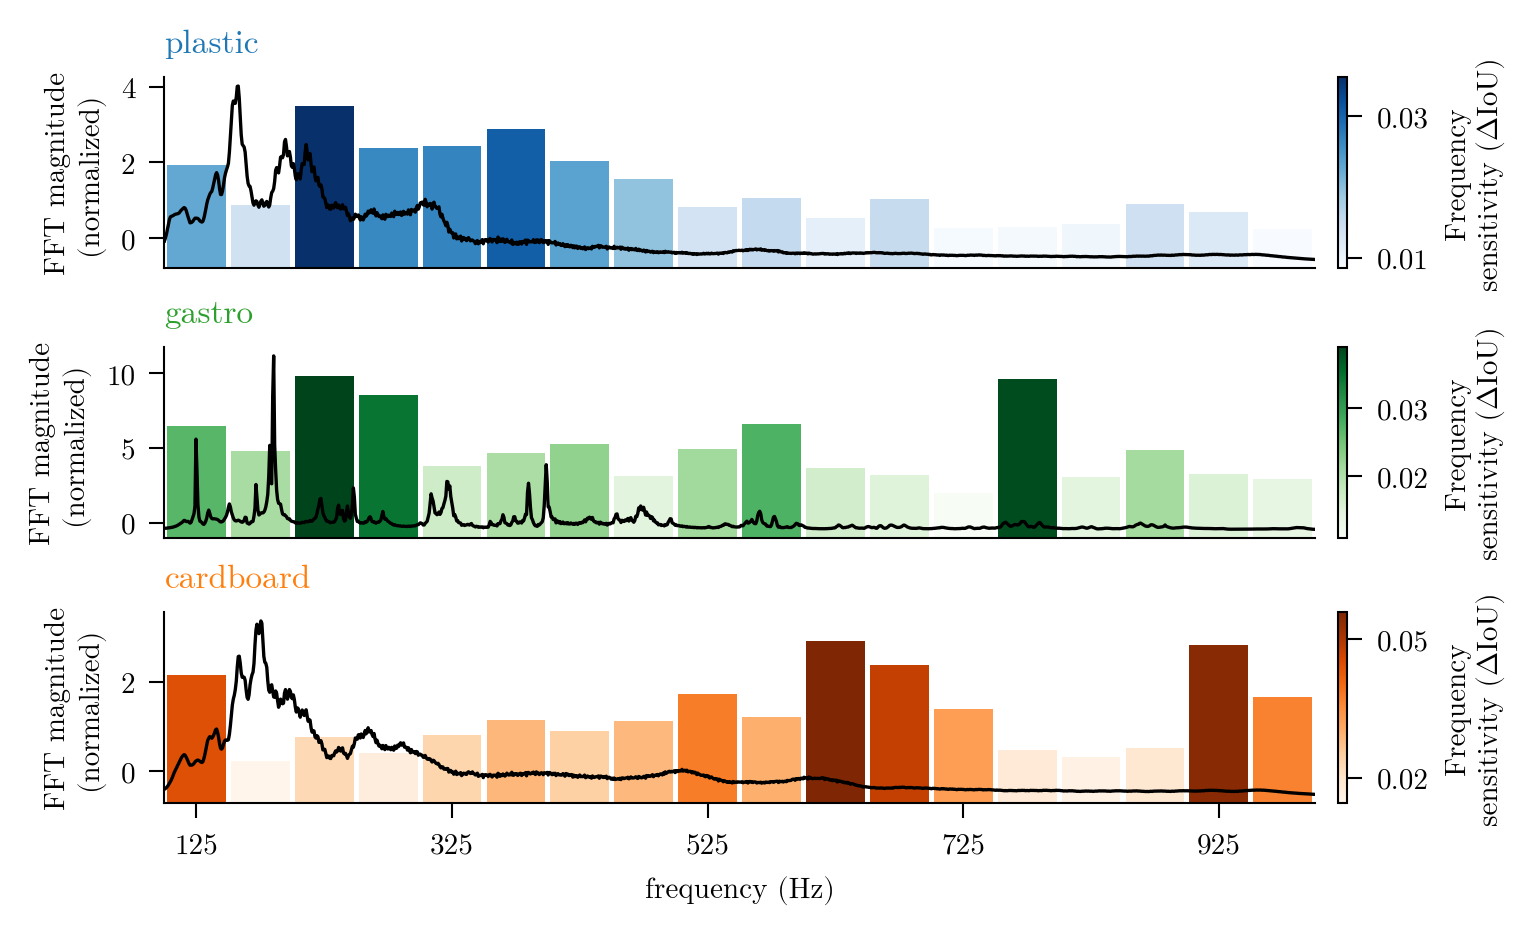

In [5]:
PAPER = {
    "font.family": LM,
    "mathtext.fontset": "custom",
    "mathtext.rm": LM,
    "mathtext.it": LM,
    "mathtext.bf": LM,
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "axes.titlesize": TITLE_SIZE,
    "axes.linewidth": .5,
    "xtick.major.width": .5,
    "ytick.major.width": .5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none",   # SVG text as editable <text> (needs Latin Modern Math installed to view)
}

with plt.rc_context(PAPER):
    fig, axes = plt.subplots(len(BX), 1, figsize=FIGSIZE, sharex=True, squeeze=False, layout="constrained")
    axes = axes[:, 0]

    for ax, b in zip(axes, BX):
        z = ZS[b]
        m = M[b]

        # bars: frequency sensitivity per band, on a hidden twin axis; colour runs from this box's min to max ΔIoU
        colors = plt.cm.ScalarMappable(plt.Normalize(m.min(), m.max()), CMAPS[b])
        bar_ax = ax.twinx()
        bar_ax.bar(BC, m, width=46, color=colors.to_rgba(m))
        bar_ax.set_ylim(0, 1.18 * m.max())
        bar_ax.axis("off")

        # line: spectrum of the same samples, drawn in front of the bars
        ax.set_zorder(bar_ax.get_zorder() + 1)
        ax.patch.set_visible(False)
        ax.plot(FHZ, z, color="k", lw=.8)
        margin = .05 * np.ptp(z)
        ax.set_ylim(z.min() - margin, z.max() + margin)
        ax.set_xlim(100, 1000)
        ax.set_ylabel("FFT magnitude\n(normalized)")
        ax.set_title(b, loc="left", color=BOXC[b])

        fig.colorbar(colors, ax=[ax, bar_ax], pad=.02, fraction=.04, label="Frequency\nsensitivity (ΔIoU)", ticks=TICKS[b])

    # x ticks only on the bottom row
    for ax in axes[:-1]:
        ax.tick_params(bottom=False)
    axes[-1].set_xticks(BC[::4])
    axes[-1].set_xlabel("frequency (Hz)")

    if OUT:
        out = ROOT / OUT
        out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out.with_suffix(".svg"))
        print("saved", out.with_suffix(".svg"))
    fig.set_dpi(300)   # notebook preview only
    plt.show()